<a href="https://colab.research.google.com/github/Daniel-Camachoo/Streaming_churn/blob/master/Projeto_churn_stream.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
import os
import pandas as pd

# Monta o Google Drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Caminho para o arquivo CSV no Drive
caminho_csv = '/content/drive/MyDrive/Ciencia_de_dados/Disc1_dados_IA_Negocios/Modulo_3/clientes_base.csv'

if os.path.exists(caminho_csv):
    df = pd.read_csv(caminho_csv)
    print("Arquivo carregado com sucesso!")
    display(df.head())
else:
    print(f"Não foi possível encontrar o arquivo no caminho especificado: {caminho_csv}")

Arquivo carregado com sucesso!


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0


**Aqui embaixo se iniciará começar a fazer uma limpeza dos dados, primeiro vai ser analisado todos os dados que significam o mesmo, mas estão com grafia diferente **

In [3]:
# Analisando a distribuição de valores nas colunas solicitadas
colunas_analise = ['plano', 'valor_mensal', 'regiao', 'canal_aquisicao']

for col in colunas_analise:
    if col in df.columns:
        print(f"\n--- Contagem de valores para a coluna: {col} ---")
        print(df[col].value_counts(dropna=False))
    else:
        print(f"\nA coluna '{col}' não foi encontrada no DataFrame.")


--- Contagem de valores para a coluna: plano ---
plano
Basico     708
BASICO     677
básico     677
Padrao     665
Padrão     654
padrão     646
premium    513
Premium    485
Name: count, dtype: int64

--- Contagem de valores para a coluna: valor_mensal ---
valor_mensal
19.9      1810
34.9      1718
55.9       894
1990.0     252
3490.0     247
5590.0     104
Name: count, dtype: int64

--- Contagem de valores para a coluna: regiao ---
regiao
Sudeste         2057
Nordeste         964
Sul              938
Centro-Oeste     488
Norte            408
?                170
Name: count, dtype: int64

--- Contagem de valores para a coluna: canal_aquisicao ---
canal_aquisicao
Organico     781
orgânico     729
Indicacao    556
IG           529
indicação    526
Instagram    519
instagram    499
Google       452
google       434
Name: count, dtype: int64


**Aqui eu ira padronizar todos os dados, retirando os acentos e colocando todos os valores no mesmo formato **

In [4]:
import unicodedata

def remover_acentos(texto):
    if not isinstance(texto, str):
        return texto
    # Normaliza o texto e remove os caracteres de acentuação
    nfkd_form = unicodedata.normalize('NFKD', texto)
    return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

# 1. Padronizar textos (minúsculo e sem acentos) para 'plano' e 'canal_aquisicao'
for col in ['plano', 'canal_aquisicao']:
    if col in df.columns:
        # Converte para string, remove espaços extras, coloca em minúsculo e remove acentos
        df[col] = df[col].astype(str).str.strip().str.lower()
        df[col] = df[col].apply(remover_acentos)

# 2. Na coluna canal_aquisicao, transformar 'ig' em 'instagram'
if 'canal_aquisicao' in df.columns:
    df['canal_aquisicao'] = df['canal_aquisicao'].replace({'ig': 'instagram'})

# 3. Na coluna valor_mensal, dividir valores maiores que 60 por 100
if 'valor_mensal' in df.columns:
    df['valor_mensal'] = df['valor_mensal'].apply(lambda x: x / 100 if x > 60 else x)

print("Limpeza e padronização concluídas!")

Limpeza e padronização concluídas!


In [5]:
# Conferindo o resultado após as alterações
for col in ['plano', 'valor_mensal', 'canal_aquisicao']:
    if col in df.columns:
        print(f"\n--- Nova contagem de valores para: {col} ---")
        print(df[col].value_counts(dropna=False))


--- Nova contagem de valores para: plano ---
plano
basico     2062
padrao     1965
premium     998
Name: count, dtype: int64

--- Nova contagem de valores para: valor_mensal ---
valor_mensal
19.9    2062
34.9    1965
55.9     998
Name: count, dtype: int64

--- Nova contagem de valores para: canal_aquisicao ---
canal_aquisicao
instagram    1547
organico     1510
indicacao    1082
google        886
Name: count, dtype: int64


In [6]:
# 1. Estatísticas descritivas das variáveis numéricas
print("--- Estatísticas Descritivas das Variáveis Numéricas ---")
display(df.describe())


--- Estatísticas Descritivas das Variáveis Numéricas ---


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn
count,5025.000000,5025.000000,5025.000000,5025.000000,5025.000000,5025.000000,5025.000000
mean,3497.592438,36.329154,32.915522,6.409751,10.653731,281.856796,0.301692
std,1443.146051,11.678632,13.266910,2.435118,6.000091,254.707091,0.459038
min,1000.000000,-2.000000,19.900000,0.000000,0.000000,0.000000,0.000000
25%,2248.000000,29.000000,19.900000,5.000000,5.000000,65.400000,0.000000
50%,3496.000000,36.000000,34.900000,7.000000,12.000000,208.600000,0.000000
75%,4747.000000,44.000000,34.900000,8.000000,15.000000,427.700000,1.000000
max,5999.000000,300.000000,55.900000,10.000000,28.000000,900.000000,1.000000


In [7]:
# 2. Estatísticas descritivas das variáveis categóricas padronizadas
print("--- Distribuição das Variáveis Categóricas Padronizadas ---")
for col in ['plano', 'canal_aquisicao']:
    if col in df.columns:
        print(f"\nProporção para a coluna: {col}")
        display(df[col].value_counts(normalize=True).round(4) * 100)


--- Distribuição das Variáveis Categóricas Padronizadas ---

Proporção para a coluna: plano


,proportion
plano,
basico,41.03
padrao,39.10
premium,19.86



Proporção para a coluna: canal_aquisicao


,proportion
canal_aquisicao,
instagram,30.79
organico,30.05
indicacao,21.53
google,17.63


In [8]:
# Verificando a quantidade de valores nulos por coluna
print("--- Quantidade de Valores Nulos por Coluna ---")
valores_nulos = df.isnull().sum()
display(valores_nulos[valores_nulos > 0] if valores_nulos.sum() > 0 else "Nenhum valor nulo encontrado!")

--- Quantidade de Valores Nulos por Coluna ---


,0
data_cancelamento,3509
data_ultimo_acesso,50
motivo_cancelamento,3509


In [9]:
# Exibindo a contagem completa de nulos em todas as colunas
display(df.isnull().sum().to_frame(name='Total de Nulos'))

,Total de Nulos
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


**Agora vou transformar tudo que for data no formato datetime, tirar as linhas em que a região é um ponto de interrogação e pedir mais anomalias.**

In [10]:
import pandas as pd
import numpy as np

# 1. Converter colunas de datas para datetime
colunas_datas = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']
for col in colunas_datas:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

# 2. Remover linhas com '?' na coluna regiao
if 'regiao' in df.columns:
    df = df[df['regiao'] != '?']

# 3. Remover idades inválidas (idades menores que 0 ou maiores que 100)
if 'idade' in df.columns:
    df = df[(df['idade'] >= 0) & (df['idade'] <= 100)]

print("Conversões e filtros iniciais aplicados com sucesso!")

Conversões e filtros iniciais aplicados com sucesso!


In [13]:
# 4. Calcular diferenças temporais
# Diferença entre assinatura e último acesso
if 'data_assinatura' in df.columns and 'data_ultimo_acesso' in df.columns:
    df['tempo_ate_ultimo_acesso'] = df['data_ultimo_acesso'] - df['data_assinatura']

# Diferença entre assinatura e cancelamento (tempo de vida do cliente ou tenure)
if 'data_assinatura' in df.columns and 'data_cancelamento' in df.columns:
    df['tempo_vida_cliente'] = df['data_cancelamento'] - df['data_assinatura']

# Diferença entre cancelamento e último acesso (para verificar se houve acessos após o cancelamento)
if 'data_cancelamento' in df.columns and 'data_ultimo_acesso' in df.columns:
    df['acesso_apos_cancelamento'] = df['data_ultimo_acesso'] - df['data_cancelamento']

print("Colunas de intervalos temporais criadas!")
display(df[['tempo_ate_ultimo_acesso', 'tempo_vida_cliente', 'acesso_apos_cancelamento']].describe())

Colunas de intervalos temporais criadas!


,tempo_ate_ultimo_acesso,tempo_vida_cliente,acesso_apos_cancelamento
count,4798,1455,1440
mean,373 days 13:35:08.378491036,220 days 20:54:55.670103092,-21 days +00:04:00
std,277 days 22:37:30.818067656,146 days 07:17:01.719099358,10 days 18:43:56.838841218
min,-47 days +00:00:00,11 days 00:00:00,-137 days +00:00:00
25%,163 days 00:00:00,118 days 00:00:00,-30 days +00:00:00
50%,308 days 00:00:00,181 days 00:00:00,-21 days +00:00:00
75%,514 days 00:00:00,289 days 00:00:00,-12 days +00:00:00
max,1809 days 00:00:00,1067 days 00:00:00,-3 days +00:00:00


In [12]:
# 5. Investigar anomalias com base nas datas
print("--- Verificando anomalias temporais ---")

# Anomalia A: Último acesso registrado antes da data de assinatura
if 'tempo_ate_ultimo_acesso' in df.columns:
    acesso_retroativo = df[df['tempo_ate_ultimo_acesso'] < pd.Timedelta(0)]
    print(f"Clientes com último acesso anterior à assinatura: {len(acesso_retroativo)}")

# Anomalia B: Acesso após a data de cancelamento
if 'acesso_apos_cancelamento' in df.columns:
    acesso_indevido = df[df['acesso_apos_cancelamento'] > pd.Timedelta(0)]
    print(f"Clientes com último acesso posterior ao cancelamento: {len(acesso_indevido)}")

--- Verificando anomalias temporais ---
Clientes com último acesso anterior à assinatura: 1
Clientes com último acesso posterior ao cancelamento: 0


In [14]:
# Exibir as primeiras 5 linhas do DataFrame atualizado
display(df.head())

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,tempo_ate_ultimo_acesso,tempo_vida_cliente,acesso_apos_cancelamento
0,5746,36,basico,Anual,19.9,Sudeste,indicacao,6,2023-04-11,NaT,2024-01-29,2024-01-31,15,276.0,NaN,0,293 days,NaT,NaT
1,4100,48,padrao,Mensal,34.9,Sudeste,organico,8,2022-06-02,NaT,2024-01-30,2024-01-31,14,394.9,NaN,0,607 days,NaT,NaT
2,4690,48,premium,Mensal,55.9,Nordeste,organico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1,590 days,607 days,-17 days
3,3454,46,basico,Anual,19.9,Sul,google,10,2023-04-02,NaT,2024-01-13,2024-01-31,19,385.0,NaN,0,286 days,NaT,NaT
4,1437,46,basico,Mensal,19.9,Norte,indicacao,8,2023-04-21,NaT,2024-01-16,2024-01-31,11,205.3,NaN,0,270 days,NaT,NaT


In [15]:
# Informações estruturais das colunas e tipos de dados
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4848 entries, 0 to 5024
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype          
---  ------                    --------------  -----          
 0   cliente_id                4848 non-null   int64          
 1   idade                     4848 non-null   int64          
 2   plano                     4848 non-null   object         
 3   ciclo                     4848 non-null   object         
 4   valor_mensal              4848 non-null   float64        
 5   regiao                    4848 non-null   object         
 6   canal_aquisicao           4848 non-null   object         
 7   nps                       4848 non-null   int64          
 8   data_assinatura           4848 non-null   datetime64[ns] 
 9   data_cancelamento         1455 non-null   datetime64[ns] 
 10  data_ultimo_acesso        4798 non-null   datetime64[ns] 
 11  data_extracao             4848 non-null   datetime64[ns] 
 12  dias_ativos

In [16]:
# Identificando as colunas pelos índices 8, 9 e 10
col_8 = df.columns[8]   # data_assinatura
col_9 = df.columns[9]   # data_cancelamento
col_10 = df.columns[10] # data_ultimo_acesso

print(f"Colunas identificadas: Índice 8 = '{col_8}', Índice 9 = '{col_9}', Índice 10 = '{col_10}'\n")

# Criando as novas colunas com as diferenças pareadas
df['dif_cancelamento_assinatura'] = df[col_9] - df[col_8]
df['dif_ultimo_acesso_assinatura'] = df[col_10] - df[col_8]
df['dif_ultimo_acesso_cancelamento'] = df[col_10] - df[col_9]

# Selecionando as novas colunas para calcular as estatísticas
colunas_dif = ['dif_cancelamento_assinatura', 'dif_ultimo_acesso_assinatura', 'dif_ultimo_acesso_cancelamento']

print("Estatísticas Descritivas das Novas Colunas de Diferença:")
display(df[colunas_dif].describe())


Colunas identificadas: Índice 8 = 'data_assinatura', Índice 9 = 'data_cancelamento', Índice 10 = 'data_ultimo_acesso'

Estatísticas Descritivas das Novas Colunas de Diferença:


,dif_cancelamento_assinatura,dif_ultimo_acesso_assinatura,dif_ultimo_acesso_cancelamento
count,1455,4798,1440
mean,220 days 20:54:55.670103092,373 days 13:35:08.378491036,-21 days +00:04:00
std,146 days 07:17:01.719099358,277 days 22:37:30.818067656,10 days 18:43:56.838841218
min,11 days 00:00:00,-47 days +00:00:00,-137 days +00:00:00
25%,118 days 00:00:00,163 days 00:00:00,-30 days +00:00:00
50%,181 days 00:00:00,308 days 00:00:00,-21 days +00:00:00
75%,289 days 00:00:00,514 days 00:00:00,-12 days +00:00:00
max,1067 days 00:00:00,1809 days 00:00:00,-3 days +00:00:00


In [17]:
# 1. Remover linhas que tenham valores negativos na coluna 'dif_ultimo_acesso_assinatura'
if 'dif_ultimo_acesso_assinatura' in df.columns:
    df = df[df['dif_ultimo_acesso_assinatura'] >= pd.Timedelta(0)]

# 2. Extrair apenas a quantidade de dias (como valores numéricos inteiros)
colunas_dif = ['dif_cancelamento_assinatura', 'dif_ultimo_acesso_assinatura', 'dif_ultimo_acesso_cancelamento']

for col in colunas_dif:
    if col in df.columns:
        df[col] = df[col].dt.days

print("Filtragem e conversão para apenas dias concluídas com sucesso!")

# Exibir as novas estatísticas descritivas
display(df[colunas_dif].describe())

Filtragem e conversão para apenas dias concluídas com sucesso!


/tmp/ipykernel_972/2981514357.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].dt.days


,dif_cancelamento_assinatura,dif_ultimo_acesso_assinatura,dif_ultimo_acesso_cancelamento
count,1439.000000,4797.000000,1439.000000
mean,220.378735,373.653742,-20.916609
std,146.046748,277.905334,10.340987
min,11.000000,0.000000,-39.000000
25%,118.000000,163.000000,-30.000000
50%,181.000000,308.000000,-21.000000
75%,288.000000,514.000000,-12.000000
max,1067.000000,1809.000000,-3.000000


In [18]:
# 1. Identificar colunas numéricas (tipos int, float ou timedelta)
colunas_numericas = df.select_dtypes(include=['int64', 'float64', 'timedelta64[ns]']).columns.tolist()
print(f"Colunas Numéricas Identificadas: {colunas_numericas}\n")

# 2. Exibir estatísticas descritivas das colunas numéricas
print("--- Estatísticas Descritivas ---")
display(df[colunas_numericas].describe())

# 3. Exibir a quantidade de valores nulos em cada coluna numérica
print("\n--- Quantidade de Nulos por Coluna Numérica ---")
display(df[colunas_numericas].isnull().sum().to_frame(name='Total de Nulos'))

Colunas Numéricas Identificadas: ['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'tempo_ate_ultimo_acesso', 'tempo_vida_cliente', 'acesso_apos_cancelamento', 'dif_cancelamento_assinatura', 'dif_ultimo_acesso_assinatura', 'dif_ultimo_acesso_cancelamento']

--- Estatísticas Descritivas ---


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,tempo_ate_ultimo_acesso,tempo_vida_cliente,acesso_apos_cancelamento,dif_cancelamento_assinatura,dif_ultimo_acesso_assinatura,dif_ultimo_acesso_cancelamento
count,4797.000000,4797.000000,4797.000000,4797.000000,4797.000000,4797.000000,4797.000000,4797,1439,1439,1439.000000,4797.000000,1439.000000
mean,3499.001459,36.229935,32.944403,6.416302,10.682927,283.656535,0.299979,373 days 15:41:23.302063788,220 days 09:05:22.724113968,-21 days +02:00:05.003474636,220.378735,373.653742,-20.916609
std,1443.643076,10.697109,13.321845,2.429217,5.993824,255.426032,0.458296,277 days 21:43:40.824178792,146 days 01:07:19.057750502,10 days 08:11:01.298884064,146.046748,277.905334,10.340987
min,1000.000000,0.000000,19.900000,0.000000,0.000000,0.000000,0.000000,0 days 00:00:00,11 days 00:00:00,-39 days +00:00:00,11.000000,0.000000,-39.000000
25%,2249.000000,28.000000,19.900000,5.000000,5.000000,65.800000,0.000000,163 days 00:00:00,118 days 00:00:00,-30 days +00:00:00,118.000000,163.000000,-30.000000
50%,3498.000000,36.000000,34.900000,7.000000,12.000000,211.300000,0.000000,308 days 00:00:00,181 days 00:00:00,-21 days +00:00:00,181.000000,308.000000,-21.000000
75%,4750.000000,44.000000,34.900000,8.000000,15.000000,430.300000,1.000000,514 days 00:00:00,288 days 00:00:00,-12 days +00:00:00,288.000000,514.000000,-12.000000
max,5999.000000,78.000000,55.900000,10.000000,28.000000,900.000000,1.000000,1809 days 00:00:00,1067 days 00:00:00,-3 days +00:00:00,1067.000000,1809.000000,-3.000000



--- Quantidade de Nulos por Coluna Numérica ---


,Total de Nulos
cliente_id,0
idade,0
valor_mensal,0
nps,0
dias_ativos_ult_mes,0
horas_assistidas_total,0
churn,0
tempo_ate_ultimo_acesso,0
tempo_vida_cliente,3358
acesso_apos_cancelamento,3358


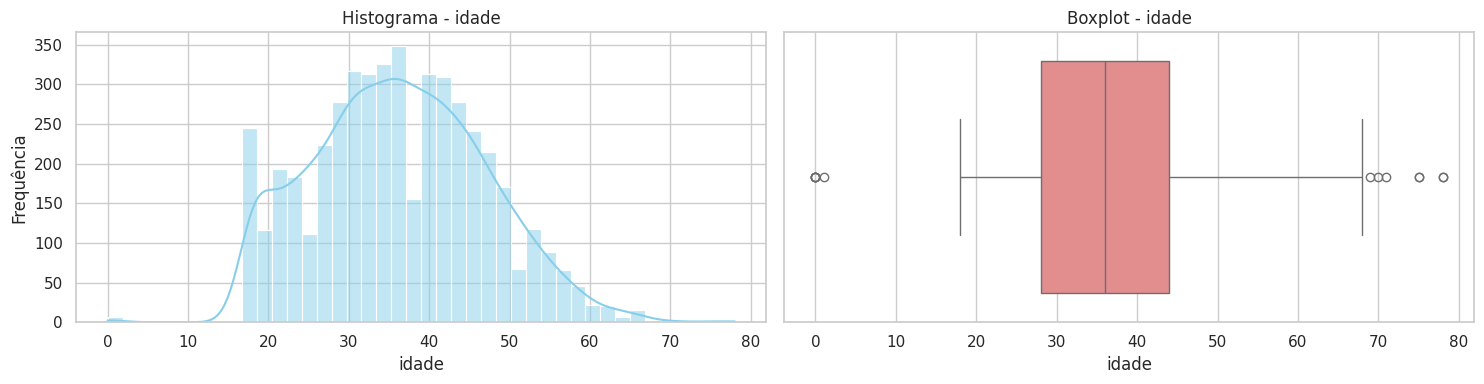

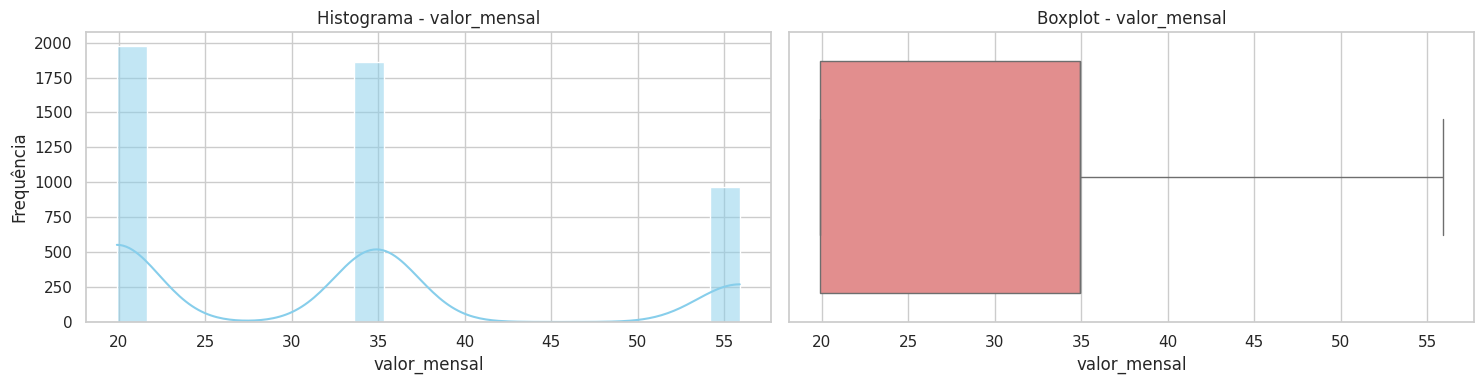

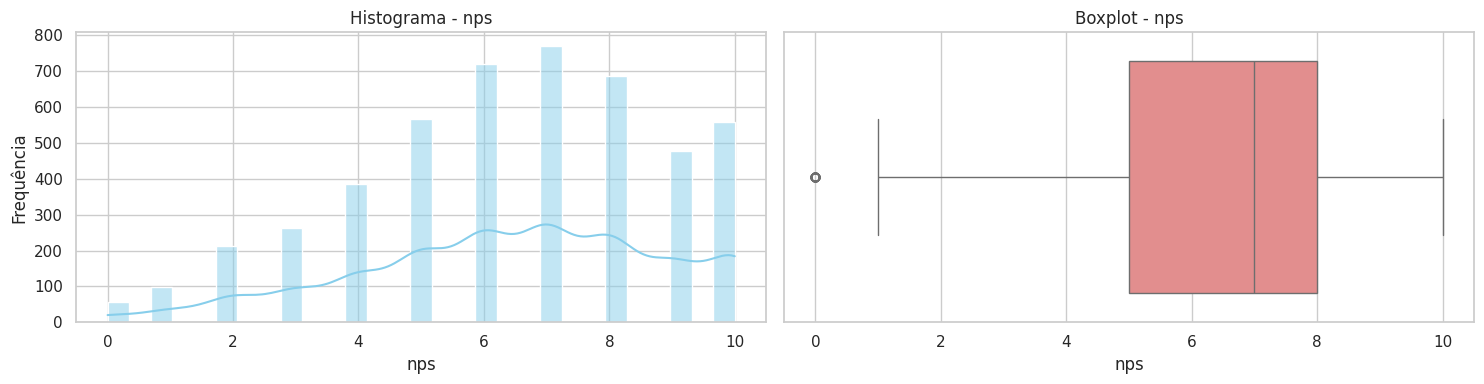

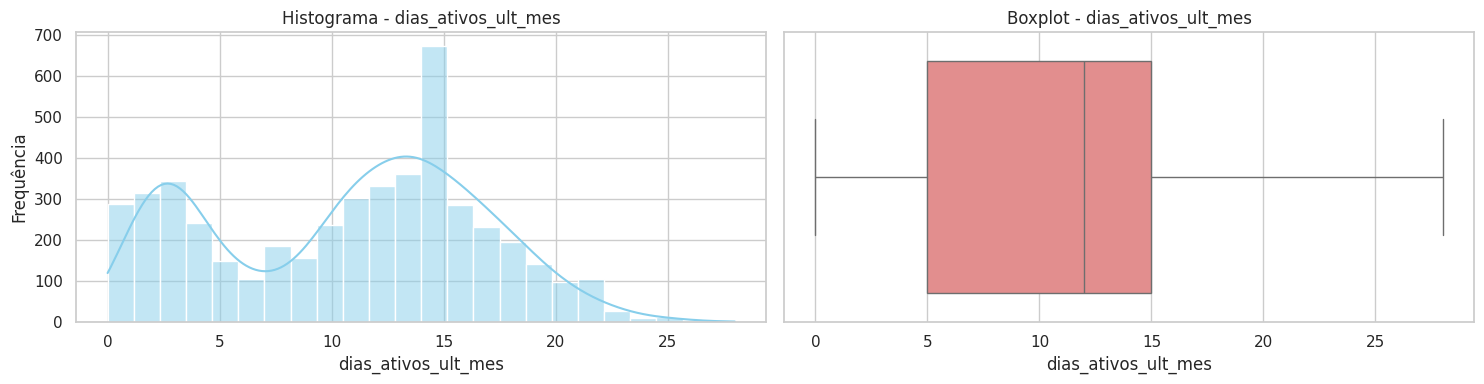

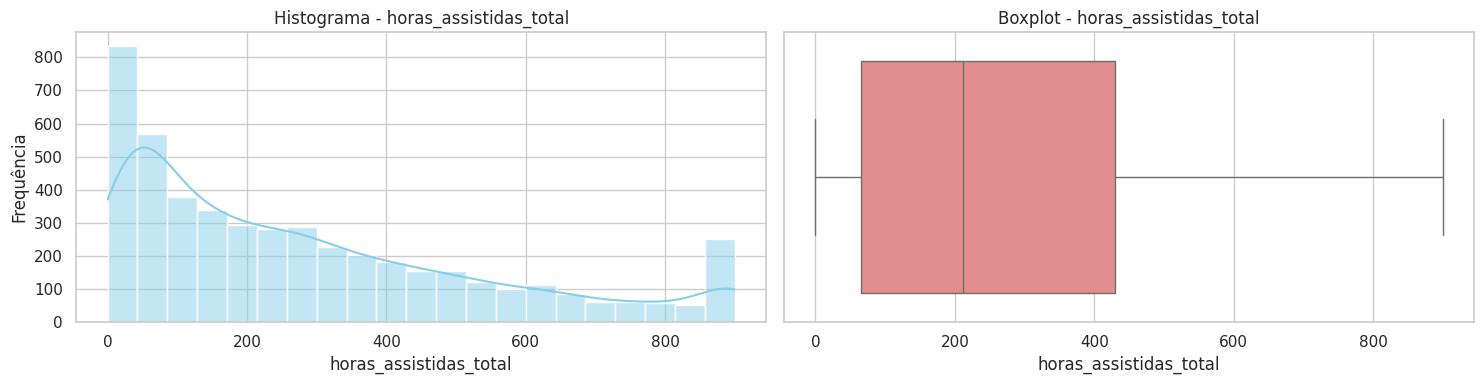

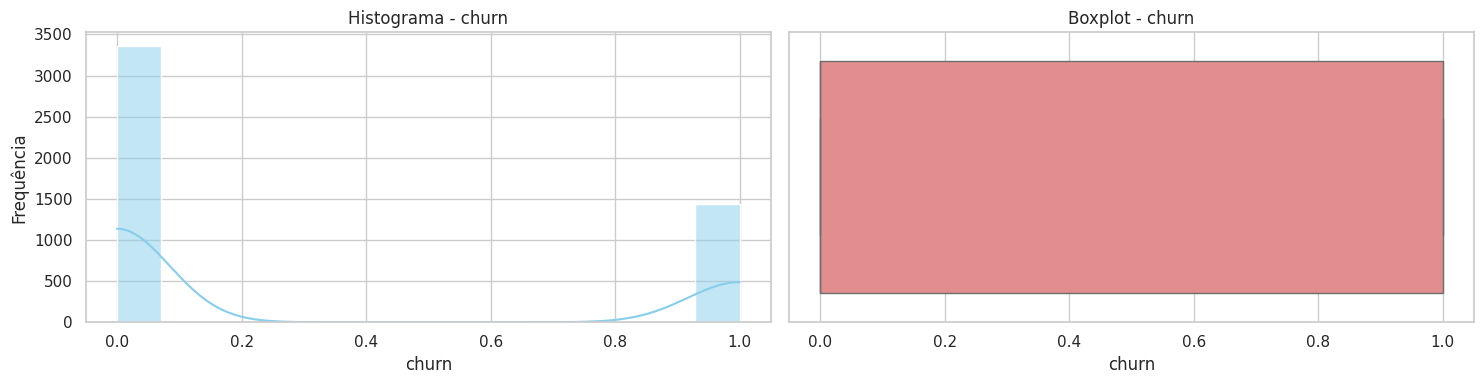

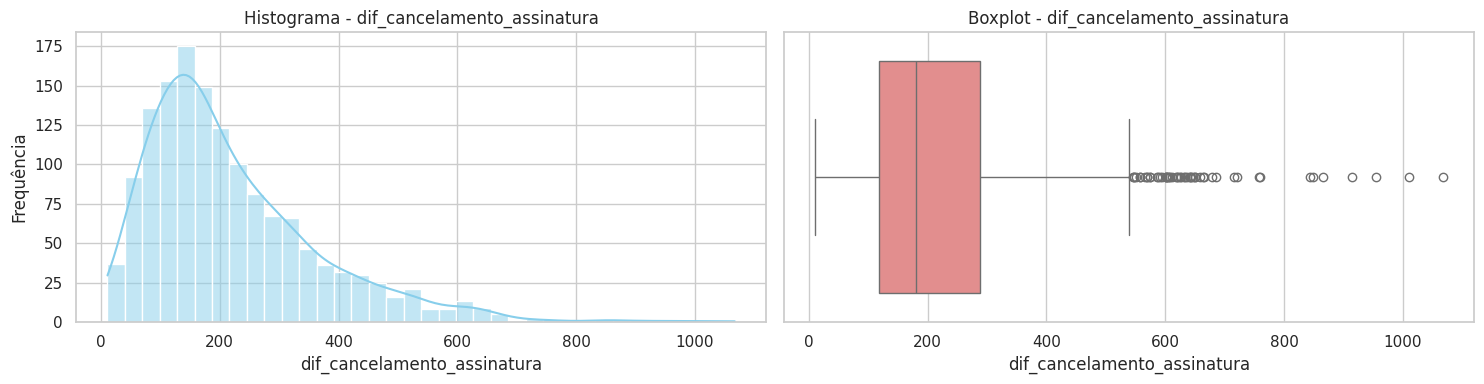

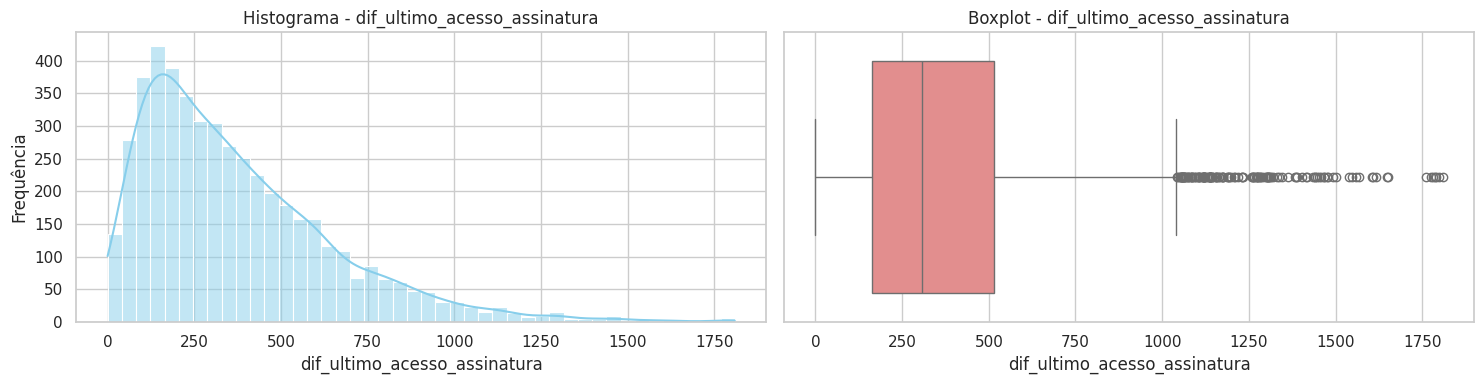

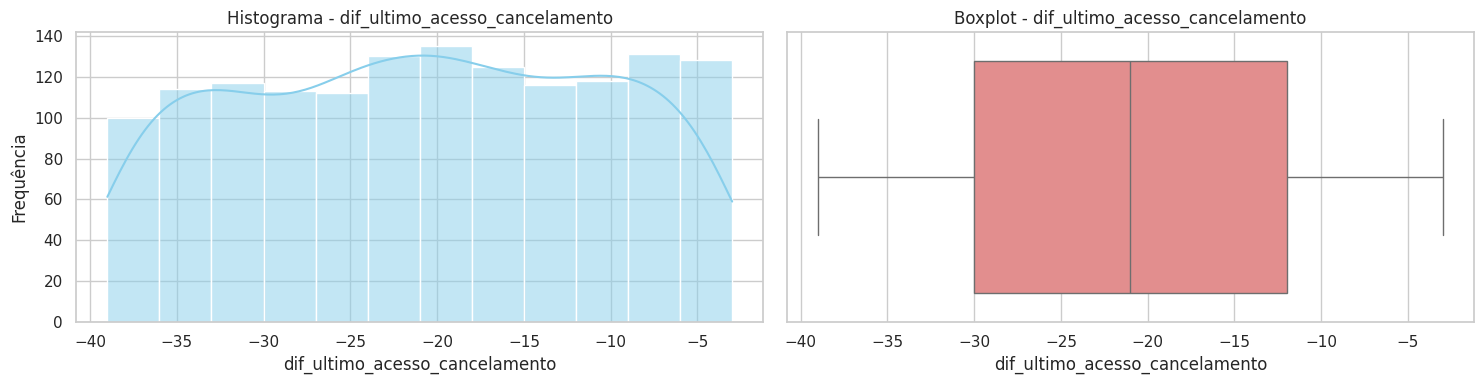

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import unicodedata
import os

# --- 1. Recarregar e limpar o DataFrame para garantir o estado ideal das variáveis ---
caminho_csv = '/content/drive/MyDrive/Ciencia_de_dados/Disc1_dados_IA_Negocios/Modulo_3/clientes_base.csv'

if os.path.exists(caminho_csv):
    df = pd.read_csv(caminho_csv)

    def remover_acentos(texto):
        if not isinstance(texto, str):
            return texto
        nfkd_form = unicodedata.normalize('NFKD', texto)
        return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

    # Padronizações de categóricas e valores mensais
    for col in ['plano', 'canal_aquisicao']:
        df[col] = df[col].astype(str).str.strip().str.lower().apply(remover_acentos)
    df['canal_aquisicao'] = df['canal_aquisicao'].replace({'ig': 'instagram'})
    df['valor_mensal'] = df['valor_mensal'].apply(lambda x: x / 100 if x > 60 else x)

    # Filtros e conversões temporais
    df = df[df['regiao'] != '?']
    df = df[(df['idade'] >= 0) & (df['idade'] <= 100)]

    colunas_datas = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']
    for col in colunas_datas:
        df[col] = pd.to_datetime(df[col], errors='coerce')

    # Criar e converter colunas de diferença pareada para dias (int)
    df['dif_cancelamento_assinatura'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days
    df['dif_ultimo_acesso_assinatura'] = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days
    df['dif_ultimo_acesso_cancelamento'] = (df['data_ultimo_acesso'] - df['data_cancelamento']).dt.days

    # Remover outliers de data de assinatura com valor negativo
    df = df[df['dif_ultimo_acesso_assinatura'] >= 0]

    # --- 2. Plotar Boxplots e Histogramas ---
    colunas_plot = [
        'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes',
        'horas_assistidas_total', 'churn', 'dif_cancelamento_assinatura',
        'dif_ultimo_acesso_assinatura', 'dif_ultimo_acesso_cancelamento'
    ]

    colunas_existentes = [col for col in colunas_plot if col in df.columns]
    sns.set_theme(style="whitegrid")

    for col in colunas_existentes:
        fig, axes = plt.subplots(1, 2, figsize=(15, 4))
        dados_plot = df[col].dropna()

        # Histograma
        sns.histplot(dados_plot, kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f'Histograma - {col}')
        axes[0].set_xlabel(col)
        axes[0].set_ylabel('Frequência')

        # Boxplot
        sns.boxplot(x=dados_plot, ax=axes[1], color='lightcoral')
        axes[1].set_title(f'Boxplot - {col}')
        axes[1].set_xlabel(col)

        plt.tight_layout()
        plt.show()
else:
    print(f"Não foi possível carregar o arquivo em: {caminho_csv}")

In [4]:
# Filtrar o DataFrame para idades entre 18 e 90 anos (inclusive)
df = df[(df['idade'] >= 18) & (df['idade'] <= 90)]

# Verificar os limites atuais de idade para confirmar o filtro
print(f"Nova idade mínima: {df['idade'].min()}")
print(f"Nova idade máxima: {df['idade'].max()}")
print(f"Total de linhas remanescentes: {len(df)}")

Nova idade mínima: 18
Nova idade máxima: 78
Total de linhas remanescentes: 4791


In [5]:
# 1. Converter tempo_vida_cliente para meses (considerando mês comercial de 30 dias)
# Convertendo a diferença timedelta para número de dias e depois dividindo por 30
df['tempo_vida_cliente'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days / 30.0

# 2. Criar coluna 'recencia': diferença em dias entre a data de extração e a de último acesso
df['recencia'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# 3. Criar coluna 'receita_acumulada': valor_mensal * tempo_vida_cliente
# Para clientes que ainda estão ativos (tempo_vida_cliente nulo), a receita acumulada é calculada
# usando o tempo até o último acesso registrado, ou preenchida conforme lógica de negócio.
# Vamos aplicar o tempo_vida_cliente direto e exibir uma amostra dos resultados.
df['receita_acumulada'] = df['valor_mensal'] * df['tempo_vida_cliente']

# Visualizando o resultado das novas alterações
print("Alterações realizadas com sucesso!")
display(df[['cliente_id', 'tempo_vida_cliente', 'recencia', 'valor_mensal', 'receita_acumulada']].head(10))

Alterações realizadas com sucesso!


,cliente_id,tempo_vida_cliente,recencia,valor_mensal,receita_acumulada
0,5746,NaN,2,19.9,NaN
1,4100,NaN,1,34.9,NaN
2,4690,20.233333,457,55.9,1131.043333
3,3454,NaN,18,19.9,NaN
4,1437,NaN,15,19.9,NaN
5,1521,NaN,11,55.9,NaN
7,3842,NaN,19,34.9,NaN
8,1958,7.833333,55,19.9,155.883333
9,3475,NaN,6,19.9,NaN
12,5127,NaN,29,34.9,NaN


In [6]:
import numpy as np

# 1. Definir a data final: data_cancelamento se preenchida, caso contrário data_extracao
data_final = df['data_cancelamento'].fillna(df['data_extracao'])

# 2. Calcular tempo_vida_cliente em meses (considerando mês de 30 dias)
df['tempo_vida_cliente'] = (data_final - df['data_assinatura']).dt.days / 30.0

# 3. Recalcular a receita_acumulada com base no novo tempo_vida_cliente
df['receita_acumulada'] = df['valor_mensal'] * df['tempo_vida_cliente']

# Exibir uma amostra contendo clientes ativos (churn = 0) e cancelados (churn = 1)
print("--- Amostra do DataFrame atualizado com a nova regra de tempo de vida ---")
display(df[['cliente_id', 'churn', 'data_assinatura', 'data_cancelamento', 'data_extracao', 'tempo_vida_cliente', 'receita_acumulada']].head(10))


--- Amostra do DataFrame atualizado com a nova regra de tempo de vida ---


,cliente_id,churn,data_assinatura,data_cancelamento,data_extracao,tempo_vida_cliente,receita_acumulada
0,5746,0,2023-04-11,NaT,2024-01-31,9.833333,195.683333
1,4100,0,2022-06-02,NaT,2024-01-31,20.266667,707.306667
2,4690,1,2021-03-20,2022-11-17,2024-01-31,20.233333,1131.043333
3,3454,0,2023-04-02,NaT,2024-01-31,10.133333,201.653333
4,1437,0,2023-04-21,NaT,2024-01-31,9.500000,189.050000
5,1521,0,2022-11-22,NaT,2024-01-31,14.500000,810.550000
7,3842,0,2022-01-21,NaT,2024-01-31,24.666667,860.866667
8,1958,1,2023-04-26,2023-12-17,2024-01-31,7.833333,155.883333
9,3475,0,2023-10-07,NaT,2024-01-31,3.866667,76.946667
12,5127,0,2023-05-16,NaT,2024-01-31,8.666667,302.466667


In [7]:
# Estatísticas descritivas para validar as novas colunas calculadas
print("--- Estatísticas Descritivas das Novas Colunas ---")
display(df[['tempo_vida_cliente', 'recencia', 'receita_acumulada']].describe())


--- Estatísticas Descritivas das Novas Colunas ---


,tempo_vida_cliente,recencia,receita_acumulada
count,4791.000000,4791.00000,4791.000000
mean,13.003681,40.36986,430.862785
std,9.226295,55.04656,373.021984
min,0.033333,0.00000,0.663333
25%,6.033333,10.00000,169.688333
50%,10.833333,20.00000,322.243333
75%,17.666667,44.00000,572.201667
max,60.500000,469.00000,2893.756667


In [8]:
# Exibir as colunas presentes no DataFrame unificado para conferência
print("--- Todas as colunas consolidadas no DataFrame ---")
print(df.columns.tolist())

# Exibir informações estruturais completas do DataFrame final unificado
print("\n--- Estrutura Completa do DataFrame Unificado ---")
df.info()

# Visualizar uma amostra contendo as colunas de identificação, demográficas, financeiras e temporais de uma só vez
print("\n--- Pré-visualização dos Dados Consolidados (Amostra) ---")
display(df[['cliente_id', 'idade', 'plano', 'valor_mensal', 'regiao', 'churn', 'tempo_vida_cliente', 'recencia', 'receita_acumulada']].head(5))

--- Todas as colunas consolidadas no DataFrame ---
['cliente_id', 'idade', 'plano', 'ciclo', 'valor_mensal', 'regiao', 'canal_aquisicao', 'nps', 'data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'motivo_cancelamento', 'churn', 'dif_cancelamento_assinatura', 'dif_ultimo_acesso_assinatura', 'dif_ultimo_acesso_cancelamento', 'tempo_vida_cliente', 'recencia', 'receita_acumulada']

--- Estrutura Completa do DataFrame Unificado ---
<class 'pandas.core.frame.DataFrame'>
Index: 4791 entries, 0 to 5024
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   cliente_id                      4791 non-null   int64         
 1   idade                           4791 non-null   int64         
 2   plano                           4791 non-null   object        
 3   ciclo                           4791 non-null

,cliente_id,idade,plano,valor_mensal,regiao,churn,tempo_vida_cliente,recencia,receita_acumulada
0,5746,36,basico,19.9,Sudeste,0,9.833333,2,195.683333
1,4100,48,padrao,34.9,Sudeste,0,20.266667,1,707.306667
2,4690,48,premium,55.9,Nordeste,1,20.233333,457,1131.043333
3,3454,46,basico,19.9,Sul,0,10.133333,18,201.653333
4,1437,46,basico,19.9,Norte,0,9.500000,15,189.050000


### Análise Estatística Voltada para Negócios

In [9]:
# 1. Métricas gerais de faturamento e engajamento
print("=== Métricas Gerais de Negócio e Engajamento ===")
metricas_negocio = ['valor_mensal', 'tempo_vida_cliente', 'receita_acumulada', 'nps', 'horas_assistidas_total']
display(df[metricas_negocio].describe())

=== Métricas Gerais de Negócio e Engajamento ===


,valor_mensal,tempo_vida_cliente,receita_acumulada,nps,horas_assistidas_total
count,4791.000000,4791.000000,4791.000000,4791.000000,4791.000000
mean,32.943832,13.003681,430.862785,6.415780,283.633104
std,13.323303,9.226295,373.021984,2.430142,255.478531
min,19.900000,0.033333,0.663333,0.000000,0.000000
25%,19.900000,6.033333,169.688333,5.000000,65.750000
50%,34.900000,10.833333,322.243333,7.000000,211.300000
75%,34.900000,17.666667,572.201667,8.000000,429.950000
max,55.900000,60.500000,2893.756667,10.000000,900.000000


In [10]:
# 2. Desempenho financeiro e retenção por tipo de plano
print("\n=== Desempenho de Negócio por Plano ===")
analise_plano = df.groupby('plano').agg(
    total_clientes=('cliente_id', 'count'),
    valor_mensal_medio=('valor_mensal', 'mean'),
    tempo_vida_medio_meses=('tempo_vida_cliente', 'mean'),
    receita_acumulada_media=('receita_acumulada', 'mean'),
    churn_rate=('churn', 'mean')
).reset_index()

# Converter taxa de churn para porcentagem para melhor leitura
analise_plano['churn_rate'] = (analise_plano['churn_rate'] * 100).round(2).astype(str) + '%'
display(analise_plano)


=== Desempenho de Negócio por Plano ===


,plano,total_clientes,valor_mensal_medio,tempo_vida_medio_meses,receita_acumulada_media,churn_rate
0,basico,1973,19.9,12.684406,252.419682,33.76%
1,padrao,1855,34.9,13.281833,463.535968,27.55%
2,premium,963,55.9,13.122015,733.520613,27.1%


In [11]:
# 3. Relação entre satisfação (NPS) e Churn
print("\n=== Média de Satisfação (NPS) por Status de Churn ===")
analise_nps_churn = df.groupby('churn').agg(
    total_clientes=('cliente_id', 'count'),
    nps_medio=('nps', 'mean'),
    horas_assistidas_medias=('horas_assistidas_total', 'mean')
).reset_index()

analise_nps_churn['status_cliente'] = analise_nps_churn['churn'].map({0: 'Ativo', 1: 'Cancelado'})
display(analise_nps_churn[['status_cliente', 'total_clientes', 'nps_medio', 'horas_assistidas_medias']])


=== Média de Satisfação (NPS) por Status de Churn ===


,status_cliente,total_clientes,nps_medio,horas_assistidas_medias
0,Ativo,3353,7.401133,382.400000
1,Cancelado,1438,4.118220,53.337274


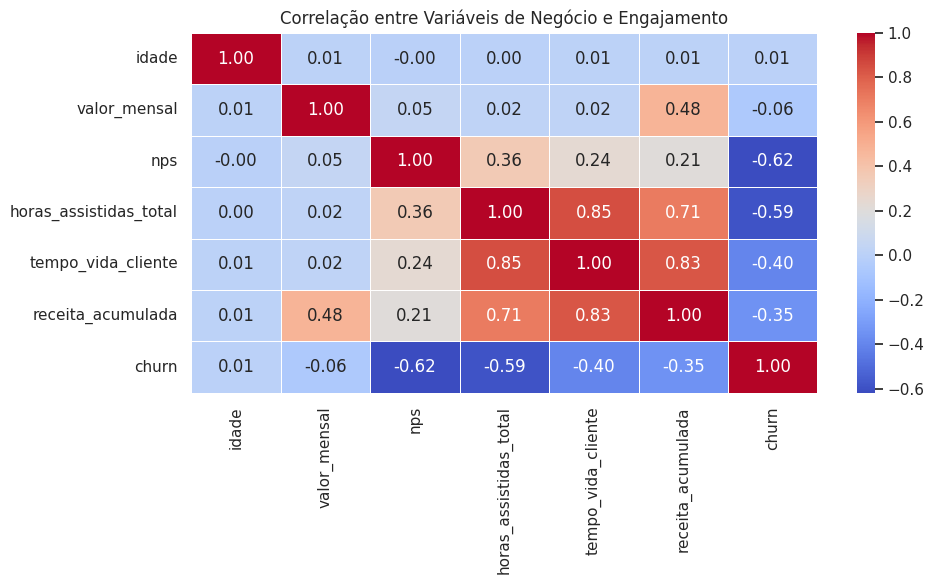

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Matriz de Correlação entre variáveis quantitativas de negócio
plt.figure(figsize=(10, 6))
colunas_corr = ['idade', 'valor_mensal', 'nps', 'horas_assistidas_total', 'tempo_vida_cliente', 'receita_acumulada', 'churn']
corr_matrix = df[colunas_corr].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlação entre Variáveis de Negócio e Engajamento')
plt.tight_layout()
plt.show()

### Análise Estratégica da Coluna de Ciclo de Faturamento

In [13]:
# 1. Distribuição geral dos clientes por ciclo de faturamento
print("=== Distribuição Absoluta e Proporcional dos Ciclos ===")
dist_ciclo = df['ciclo'].value_counts().to_frame(name='Total de Clientes')
dist_ciclo['Proporção (%)'] = (df['ciclo'].value_counts(normalize=True) * 100).round(2)
display(dist_ciclo)

=== Distribuição Absoluta e Proporcional dos Ciclos ===


,Total de Clientes,Proporção (%)
ciclo,,
Mensal,3616,75.47
Anual,1175,24.53


In [14]:
# 2. Cruzamento do Ciclo com a Taxa de Churn
print("\n=== Taxa de Churn por Ciclo de Faturamento ===")
churn_ciclo = df.groupby('ciclo').agg(
    total_clientes=('cliente_id', 'count'),
    total_cancelados=('churn', 'sum'),
    churn_rate=('churn', 'mean')
).reset_index()

churn_ciclo['churn_rate'] = (churn_ciclo['churn_rate'] * 100).round(2).astype(str) + '%'
display(churn_ciclo)


=== Taxa de Churn por Ciclo de Faturamento ===


,ciclo,total_clientes,total_cancelados,churn_rate
0,Anual,1175,352,29.96%
1,Mensal,3616,1086,30.03%


In [15]:
# 3. Impacto do Ciclo no LTV (Receita Acumulada) e Tempo de Vida
print("\n=== Métricas de Retenção e Faturamento por Ciclo ===")
financeiro_ciclo = df.groupby('ciclo').agg(
    tempo_vida_medio_meses=('tempo_vida_cliente', 'mean'),
    receita_acumulada_media=('receita_acumulada', 'mean'),
    valor_mensal_medio=('valor_mensal', 'mean')
).reset_index()

display(financeiro_ciclo)


=== Métricas de Retenção e Faturamento por Ciclo ===


,ciclo,tempo_vida_medio_meses,receita_acumulada_media,valor_mensal_medio
0,Anual,13.303887,438.423172,32.640426
1,Mensal,12.906130,428.406078,33.042423


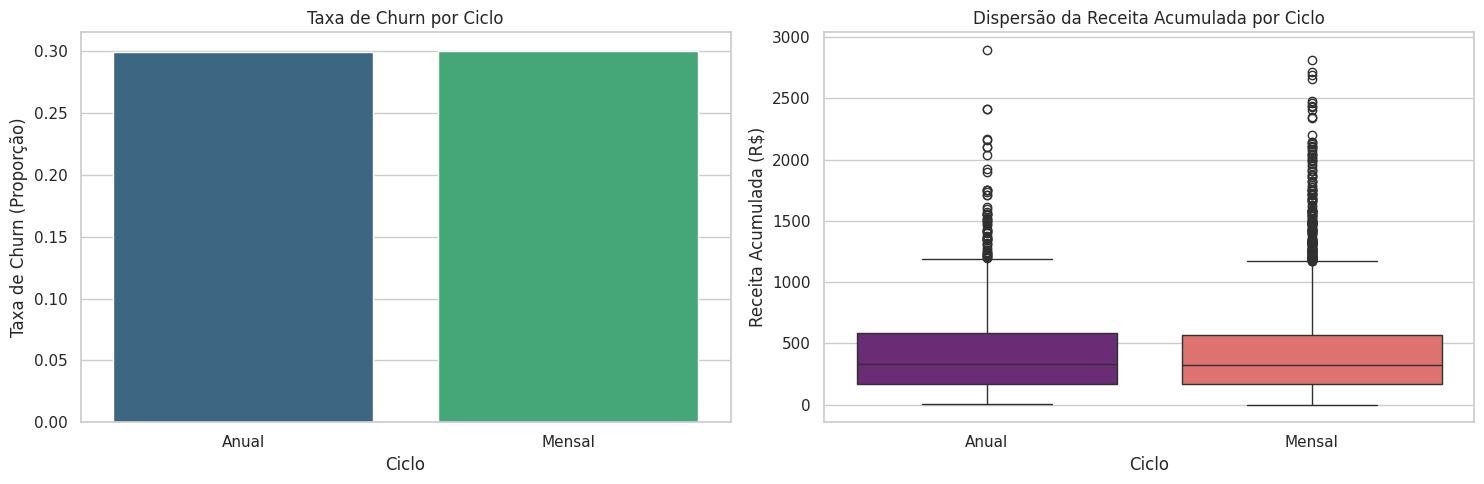

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Visualização gráfica do Churn e Receita por Ciclo
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico de barras da taxa de churn
sns.barplot(data=df, x='ciclo', y='churn', ax=axes[0], errorbar=None, palette='viridis', hue='ciclo', legend=False)
axes[0].set_title('Taxa de Churn por Ciclo')
axes[0].set_ylabel('Taxa de Churn (Proporção)')
axes[0].set_xlabel('Ciclo')

# Gráfico de Boxplot da receita acumulada
sns.boxplot(data=df, x='ciclo', y='receita_acumulada', ax=axes[1], palette='magma', hue='ciclo', legend=False)
axes[1].set_title('Dispersão da Receita Acumulada por Ciclo')
axes[1].set_ylabel('Receita Acumulada (R$)')
axes[1].set_xlabel('Ciclo')

plt.tight_layout()
plt.show()

**Conclusão análise univariada**

1- Base suja


*   Plano: "BASICO"/"Básico"/"Basico" são o mesmo plano, mas contam separados na base de dados. Sem a limpeza tinham 8 categorias diferentes quando na verdade eram para ter apenas 3.
*   Valor_mensal: "19.90"/"1990.00" são o mesmo valor, porém com alguns erros de escrita, foi feita a unificação desses valores
*   Canal_aquisicao: "IG"/"Instagram"/"instagram" são os mesmos, mas contavam como diferentes, o mesmo trabalho das anteriores foi feito nessa coluna

2- Anomalias:

*   "?" escrito na categoria região. Algumas linhas tinham essa incoerência escrita. Após analise, foi visto que era uma pequena porcentagem do total que não alterava o resultado final da base de dados, por isso foi feita a exclusão dessas linhas.
*   Pessoas com mais de 300 anos de idade e com menos de 10 anos de idade foram excluídas da lista, visto que havia incoerência nesses dados.
*   Incoerências do tipo data de assinatura depois da data de cancelamento também foram excluídas do banco de dados

Inicialmente havia 5024 linhas no dataframe e após as exclusões ficaram 4848 linhas, ocasionando uma exclusão de 3,5% do total.

3- Insights de negócio real: Somando as regiões válidas, vemos que aproximadamente 42% dos clientes são da região Sudeste, enquanto apenas 8% se concentram na região norte. Isso importa para qualquer análise regional que seja feita posterior mente, sendo na região sudeste tendo dados para conclusões mais robustas, enquanto a região norte sendo uma amostra pequena, podendo dar incertezas nas conclusões.

4- Insights de negócio:
*   o produto é predominantemente mensal,aproximadamente 75% dos clientes utilizam o plano mensal. Apesar disso, a receita é muito parecida entre os planos.

5- **A distribuição de canais é equilibrada** instagram(1547),organico(1510),indicacao(1082),google(886). Aquisição diversificada, sem dependência perigosa de um único canal.











In [6]:
import pandas as pd
import numpy as np
import unicodedata
import os

caminho_csv = '/content/drive/MyDrive/Ciencia_de_dados/Disc1_dados_IA_Negocios/Modulo_3/clientes_base.csv'

if os.path.exists(caminho_csv):
    # 1. Carregar os dados
    df = pd.read_csv(caminho_csv)

    # 2. Reaplicar tratamentos e padronizações anteriores
    def remover_acentos(texto):
        if not isinstance(texto, str):
            return texto
        nfkd_form = unicodedata.normalize('NFKD', texto)
        return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

    for col in ['plano', 'canal_aquisicao']:
        df[col] = df[col].astype(str).str.strip().str.lower().apply(remover_acentos)
    df['canal_aquisicao'] = df['canal_aquisicao'].replace({'ig': 'instagram'})
    df['valor_mensal'] = df['valor_mensal'].apply(lambda x: x / 100 if x > 60 else x)
    df = df[df['regiao'] != '?']
    df = df[(df['idade'] >= 18) & (df['idade'] <= 90)]

    colunas_datas = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']
    for col in colunas_datas:
        df[col] = pd.to_datetime(df[col], errors='coerce')

    # 3. Criar a nova coluna com a diferença em dias (nulo caso não tenha cancelado)
    df['dias_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days

    # 4. Exibir estatísticas descritivas completas para o tempo que o cliente fica (tempo de permanência)
    print("=== Estatísticas do Tempo de Permanência (em dias) dos Clientes que Cancelaram ===")
    display(df['dias_ate_cancelamento'].describe().to_frame())

    # 5. Exibir amostra
    print("\n=== Amostra de Clientes (Cancelados vs Ativos) ===")
    display(df[['cliente_id', 'data_assinatura', 'data_cancelamento', 'dias_ate_cancelamento']].head(10))
else:
    print(f"Não foi possível carregar o arquivo em: {caminho_csv}. Verifique se o Google Drive está montado corretamente.")

=== Estatísticas do Tempo de Permanência (em dias) dos Clientes que Cancelaram ===


,dias_ate_cancelamento
count,1454.000000
mean,220.977992
std,146.297384
min,11.000000
25%,118.000000
50%,181.500000
75%,289.500000
max,1067.000000



=== Amostra de Clientes (Cancelados vs Ativos) ===


,cliente_id,data_assinatura,data_cancelamento,dias_ate_cancelamento
0,5746,2023-04-11,NaT,NaN
1,4100,2022-06-02,NaT,NaN
2,4690,2021-03-20,2022-11-17,607.0
3,3454,2023-04-02,NaT,NaN
4,1437,2023-04-21,NaT,NaN
5,1521,2022-11-22,NaT,NaN
7,3842,2022-01-21,NaT,NaN
8,1958,2023-04-26,2023-12-17,235.0
9,3475,2023-10-07,NaT,NaN
11,3426,2023-08-18,2023-11-16,90.0


=== ANALISE DAS VARIAVEIS NUMERICAS VS CHURN ===


--- Analisando: idade ---


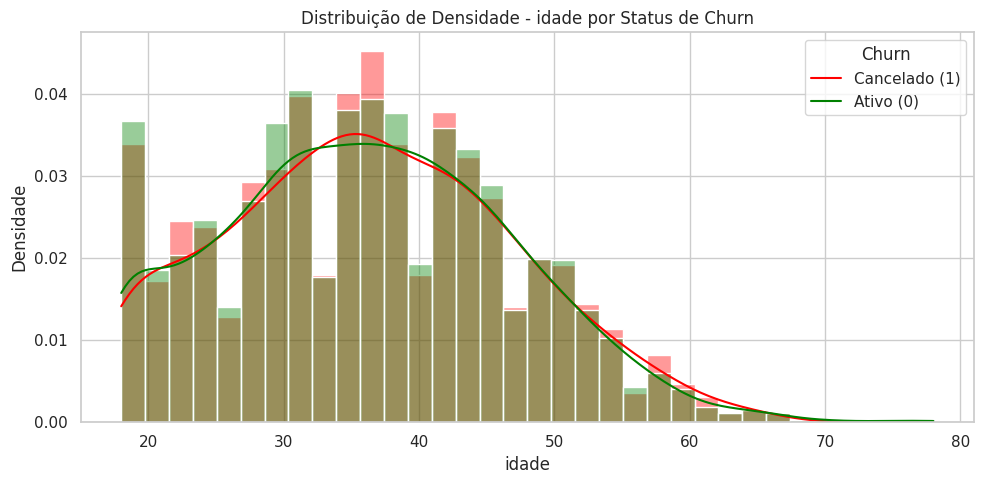

,Ativo (Churn = 0),Cancelado (Churn = 1)
count,3388.000000,1454.000000
mean,36.219303,36.390646
std,10.635492,10.593799
min,18.000000,18.000000
25%,29.000000,29.000000
50%,36.000000,36.000000
75%,44.000000,44.000000
max,78.000000,66.000000



--- Analisando: valor_mensal ---


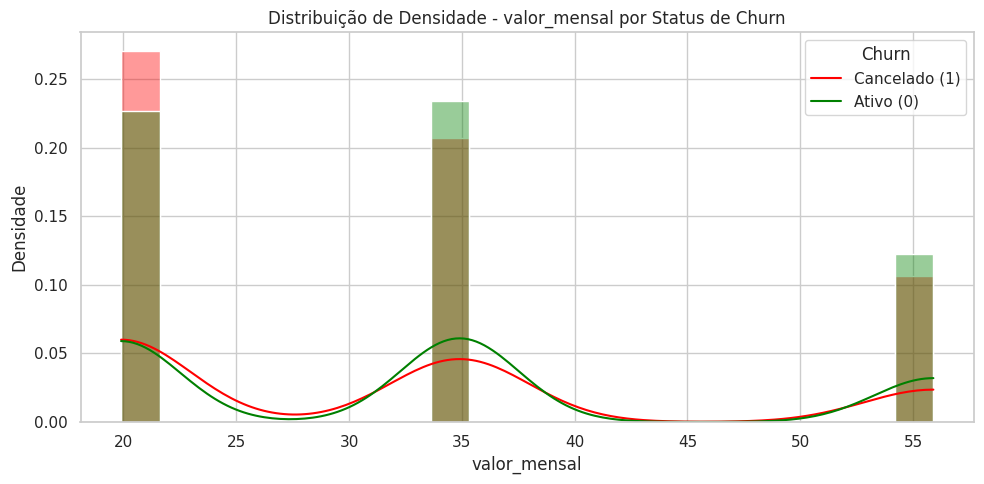

,Ativo (Churn = 0),Cancelado (Churn = 1)
count,3388.000000,1454.000000
mean,33.497403,31.774140
std,13.350036,13.229614
min,19.900000,19.900000
25%,19.900000,19.900000
50%,34.900000,34.900000
75%,34.900000,34.900000
max,55.900000,55.900000



--- Analisando: nps ---


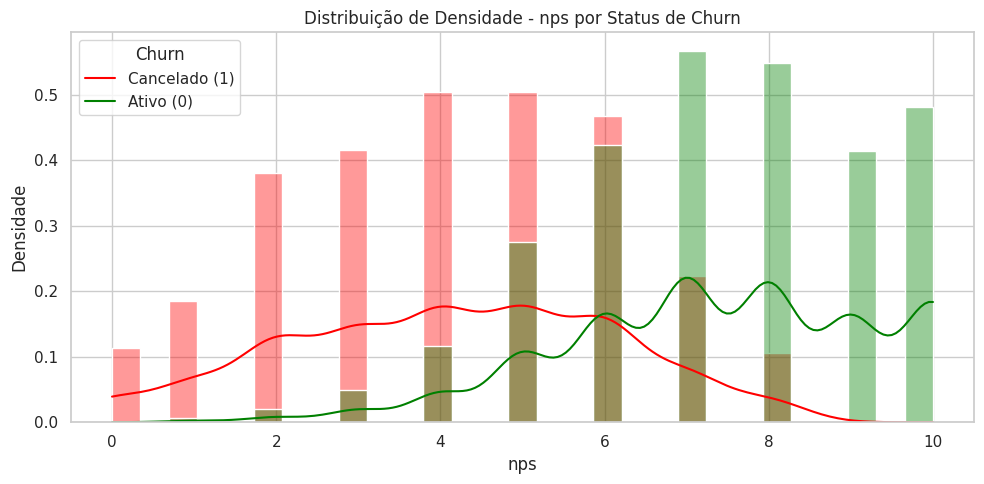

,Ativo (Churn = 0),Cancelado (Churn = 1)
count,3388.000000,1454.000000
mean,7.400236,4.118294
std,1.872310,1.988552
min,1.000000,0.000000
25%,6.000000,3.000000
50%,7.000000,4.000000
75%,9.000000,6.000000
max,10.000000,8.000000



--- Analisando: dias_ativos_ult_mes ---


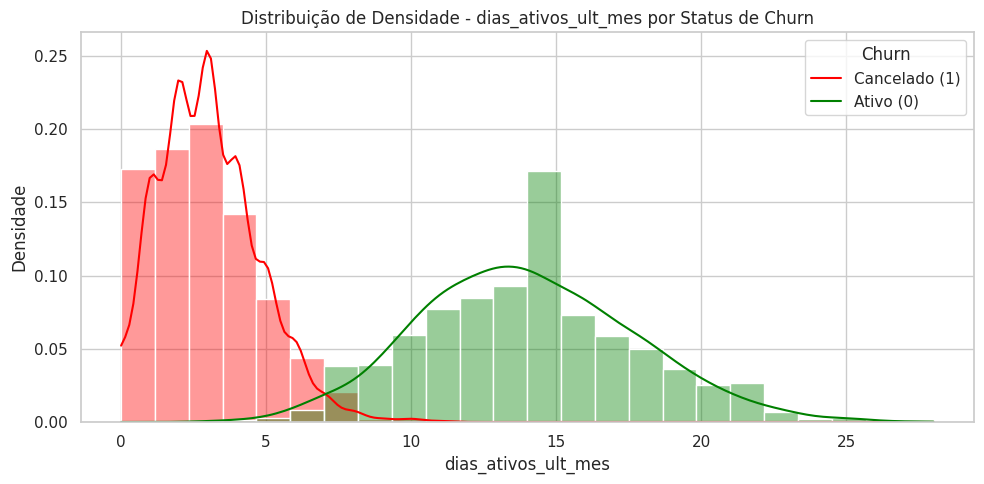

,Ativo (Churn = 0),Cancelado (Churn = 1)
count,3388.000000,1454.000000
mean,13.978158,2.984869
std,3.712123,1.713408
min,3.000000,0.000000
25%,11.000000,2.000000
50%,14.000000,3.000000
75%,16.000000,4.000000
max,28.000000,11.000000



--- Analisando: horas_assistidas_total ---


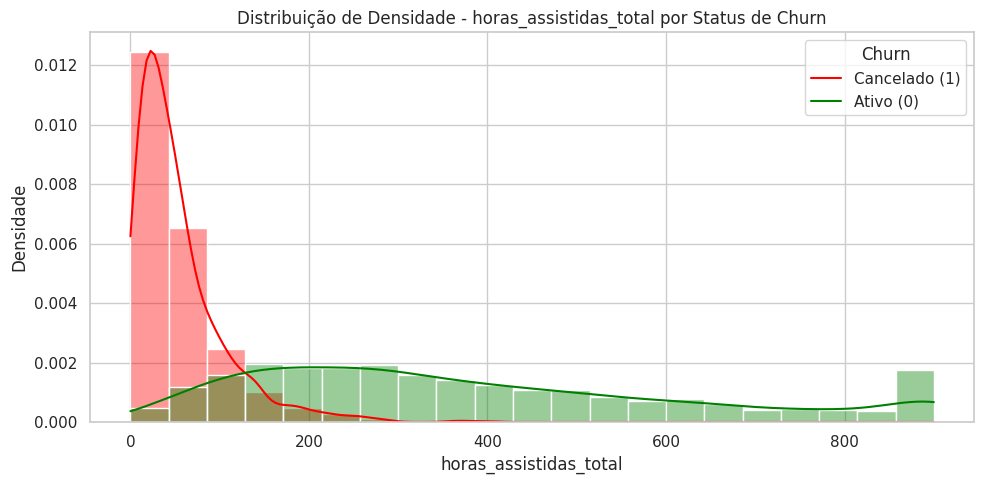

,Ativo (Churn = 0),Cancelado (Churn = 1)
count,3388.000000,1454.000000
mean,381.926063,53.401651
std,244.283579,50.162882
min,10.900000,0.000000
25%,185.700000,19.800000
50%,325.000000,39.400000
75%,534.225000,69.950000
max,900.000000,400.000000


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Definir tema do seaborn
sns.set_theme(style="whitegrid")

# Separar as colunas por tipo para análise
num_cols = ['idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'tempo_vida_cliente', 'recencia', 'receita_acumulada']
cat_cols = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

print("=== ANALISE DAS VARIAVEIS NUMERICAS VS CHURN ===\n")

for col in num_cols:
    if col in df.columns:
        print(f"\n--- Analisando: {col} ---")

        # 1. Histograma de densidade sobreposto
        plt.figure(figsize=(10, 5))
        sns.histplot(
            data=df,
            x=col,
            hue='churn',
            kde=True,
            stat='density',
            common_norm=False,
            palette={0: 'green', 1: 'red'},
            alpha=0.4
        )
        plt.title(f'Distribuição de Densidade - {col} por Status de Churn')
        plt.xlabel(col)
        plt.ylabel('Densidade')
        plt.legend(title='Churn', labels=['Cancelado (1)', 'Ativo (0)'])
        plt.tight_layout()
        plt.show()

        # 2. Tabela de estatísticas por grupo de churn
        stats_df = df.groupby('churn')[col].describe().T
        stats_df.columns = ['Ativo (Churn = 0)', 'Cancelado (Churn = 1)']
        display(stats_df)


In [10]:
print("=== ANALISE DAS VARIAVEIS CATEGORICAS VS CHURN ===\n")

total_churn_geral = df['churn'].sum()
print(f"Total geral de clientes que deram churn: {total_churn_geral}\n")

for col in cat_cols:
    if col in df.columns:
        print(f"\n--- Distribuição do Churn por {col.capitalize()} ---")

        # Agrupar e calcular métricas absolutas e as duas lógicas solicitadas
        tabela_cat = df.groupby(col).agg(
            total_clientes=('churn', 'count'),
            total_churn=('churn', 'sum'),
            taxa_churn_categoria=('churn', 'mean')
        ).reset_index()

        # Lógica original: Taxa de Churn interna da categoria
        tabela_cat['taxa_churn_categoria'] = (tabela_cat['taxa_churn_categoria'] * 100).round(2).astype(str) + '%'

        # Nova lógica: Porcentagem de representação em relação ao total GERAL de churn
        tabela_cat['%_do_total_churn'] = ((tabela_cat['total_churn'] / total_churn_geral) * 100).round(2).astype(str) + '%'

        display(tabela_cat)


=== ANALISE DAS VARIAVEIS CATEGORICAS VS CHURN ===

Total geral de clientes que deram churn: 1454


--- Distribuição do Churn por Plano ---


,plano,total_clientes,total_churn,taxa_churn_categoria,%_do_total_churn
0,basico,1989,674,33.89%,46.35%
1,padrao,1875,515,27.47%,35.42%
2,premium,978,265,27.1%,18.23%



--- Distribuição do Churn por Ciclo ---


,ciclo,total_clientes,total_churn,taxa_churn_categoria,%_do_total_churn
0,Anual,1190,359,30.17%,24.69%
1,Mensal,3652,1095,29.98%,75.31%



--- Distribuição do Churn por Regiao ---


,regiao,total_clientes,total_churn,taxa_churn_categoria,%_do_total_churn
0,Centro-Oeste,486,157,32.3%,10.8%
1,Nordeste,961,287,29.86%,19.74%
2,Norte,408,130,31.86%,8.94%
3,Sudeste,2053,605,29.47%,41.61%
4,Sul,934,275,29.44%,18.91%



--- Distribuição do Churn por Canal_aquisicao ---


,canal_aquisicao,total_clientes,total_churn,taxa_churn_categoria,%_do_total_churn
0,google,848,274,32.31%,18.84%
1,indicacao,1043,301,28.86%,20.7%
2,instagram,1497,448,29.93%,30.81%
3,organico,1454,431,29.64%,29.64%


**Conclusões análise bivariada**

Aqui estão os insights só da bivariada, com os números do notebook


1. NPS é o sinal mais forte E é um sinal honesto: o NPS é declarado ao longo da relação, não é consequência mecânica do churn. É a primeira candidata a virar alerta precoce de cancelamento.

2. Idade e valor do plano prăticamente não separam. Idade idêntica nos dois grupos (36 vs 36) e valor mensal consequencia do plano básico x premium. É um achado útil: descarta hipóteses óbvias e evita que o time gaste energia segmentando por essas variáveis.

3. Ciclo e região. Anual e mensal têm composição praticamente igual entre churners e não-churners, e a região, vemos maior diferença de churn no Norte e Centro-oeste. O caso do ciclo é contraintuitivo - o compromisso do plano anual não está segurando ninguém de forma perceptível. (Vale lembrar que 75% da base é mensal, o que reduz o contraste possível.)

4. Canal de aquisição tem efeito leve, mas com valor de negócio. Quem vem de indicação retém um pouco mais do que quem vem do google e outros canais. Conecta com decisão de marketing: a origem do cliente carrega alguma informação sobre a fidelidade dele - canais diferentes trazem clientes compropensões diferentes.

5. As variáveis de engajamento PARECEM separar espetacularmente - armadilha. Dias ativos (14 vs 3), horas assistida (449 vs 73) e recência (15 vs 130 dias) mostram as maiores diferenças de toda a análise. Mas são contaminadas por vazamento de target: a pessoa parou de usar porque saiu, não o contrário *churn causa a variável, não o contrário). A separação é quase circular - elas descrevem o churn que já aconteceu, não o antecipam. Usá-las como "causa" seria o erro mais caro da análise.


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

def remover_acentos(texto):
    if not isinstance(texto, str):
        return texto
    nfkd_form = unicodedata.normalize('NFKD', texto)
    return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

# 1. Filtrar quem deu churn
df_churn = df[df['churn'] == 1].copy()

# Padronizar a coluna motivo_cancelamento (minúsculo, sem acentos e sem espaços extras)
if 'motivo_cancelamento' in df_churn.columns:
    df_churn['motivo_cancelamento_limpo'] = df_churn['motivo_cancelamento'].astype(str).str.strip().str.lower()
    df_churn['motivo_cancelamento_limpo'] = df_churn['motivo_cancelamento_limpo'].apply(remover_acentos)
    # Remover nulos que viraram string 'nan'
    df_churn = df_churn[df_churn['motivo_cancelamento_limpo'] != 'nan']

# 2. Contar os motivos ordenados de forma decrescente
pareto_df = df_churn['motivo_cancelamento_limpo'].value_counts().reset_index()
pareto_df.columns = ['motivo_cancelamento', 'quantidade']

# 3. Calcular porcentagem individual e porcentagem acumulada
total_cancelamentos = pareto_df['quantidade'].sum()
pareto_df['porcentagem'] = (pareto_df['quantidade'] / total_cancelamentos) * 100
pareto_df['porcentagem_acumulada'] = pareto_df['porcentagem'].cumsum()

print("=== TABELA DE PARETO (DADOS HIGIENIZADOS) ===")
display(pareto_df.round(2))

# 4. Identificar motivos que concentram ~80% dos cancelamentos
motivos_80 = pareto_df[pareto_df['porcentagem_acumulada'] - pareto_df['porcentagem'] < 80]['motivo_cancelamento'].tolist()

print("\n=== PRINCIPAIS OFENSORES CONSOLIDADOS (ATÉ ~80% DO TOTAL) ===")
print(", ".join([m.capitalize() for m in motivos_80]))

=== TABELA DE PARETO (DADOS HIGIENIZADOS) ===


,motivo_cancelamento,quantidade,porcentagem,porcentagem_acumulada
0,preco,490,33.70,33.70
1,pouco conteudo novo,371,25.52,59.22
2,problema tecnico,239,16.44,75.65
3,falta de tempo,166,11.42,87.07
4,concorrente,126,8.67,95.74
5,outro,62,4.26,100.00



=== PRINCIPAIS OFENSORES CONSOLIDADOS (ATÉ ~80% DO TOTAL) ===
Preco, Pouco conteudo novo, Problema tecnico, Falta de tempo


/tmp/ipykernel_677/2805021314.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels([str(label.get_text()).capitalize() for label in ax1.get_xticklabels()], rotation=45, ha='right')


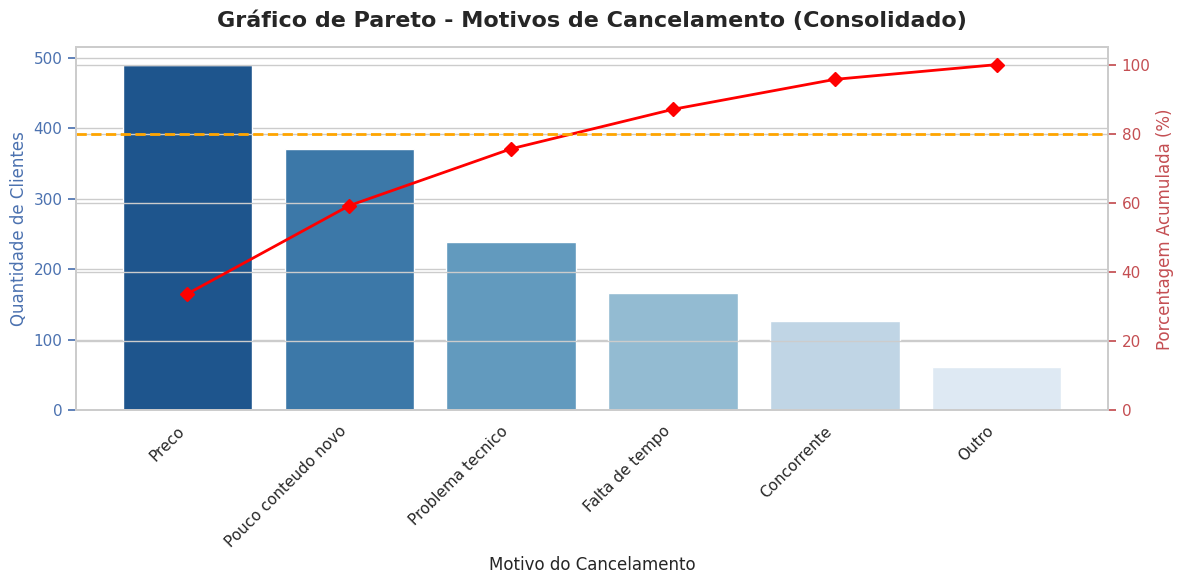

In [14]:
# 5. Plotar o Gráfico de Pareto com os dados higienizados
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo principal (Barras - Quantidade de Cancelamentos)
sns.barplot(data=pareto_df, x='motivo_cancelamento', y='quantidade', ax=ax1, palette='Blues_r', hue='motivo_cancelamento', legend=False)
ax1.set_title('Gráfico de Pareto - Motivos de Cancelamento (Consolidado)', fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel('Motivo do Cancelamento', fontsize=12)
ax1.set_ylabel('Quantidade de Clientes', fontsize=12, color='b')
ax1.tick_params(axis='y', colors='b')
ax1.set_xticklabels([str(label.get_text()).capitalize() for label in ax1.get_xticklabels()], rotation=45, ha='right')

# Eixo secundário (Linha - Porcentagem Acumulada)
ax2 = ax1.twinx()
ax2.plot(pareto_df['motivo_cancelamento'], pareto_df['porcentagem_acumulada'], color='red', marker='D', ms=7, linewidth=2, label='% Acumulado')
ax2.set_ylabel('Porcentagem Acumulada (%)', fontsize=12, color='r')
ax2.tick_params(axis='y', colors='r')
ax2.set_ylim(0, 105)

# Linha horizontal de corte em 80%
ax2.axhline(80, color='orange', linestyle='--', linewidth=2, label='Linha de Corte 80%')

plt.tight_layout()
plt.show()

**Analisando os problemas**

Utilizando como base a análise de Pareto, vê-se que aproximadamente 80% das reclamações, dos clientes que fizeram churn, são preço, conteúdo novo e problemas técnicos. Com isso, tem-se uma indicação quais pontos deve-se dar mais atenção em relação a diminuição do número de churn.